In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from pathlib import Path

In [2]:
base_dir = r"D:\Ai & Ml Diploma Content\Asssignment\CNN\Vegetable Images"

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")
validation_dir = os.path.join(base_dir, "validation")

print("Train Directory:", train_dir)
print("Test Directory:", test_dir)
print("Validation Directory:", validation_dir)

Train Directory: D:\Ai & Ml Diploma Content\Asssignment\CNN\Vegetable Images\train
Test Directory: D:\Ai & Ml Diploma Content\Asssignment\CNN\Vegetable Images\test
Validation Directory: D:\Ai & Ml Diploma Content\Asssignment\CNN\Vegetable Images\validation


In [4]:
def count_images(folder_path):
    image_counts = {}

    for class_name in os.listdir(folder_path):
        class_path = os.path.join(folder_path, class_name)

        if os.path.isdir(class_path):
            images = [
                file for file in os.listdir(class_path)
                if file.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            image_counts[class_name] = len(images)

    return image_counts


train_counts = count_images(train_dir)
test_counts = count_images(test_dir)
validation_counts = count_images(validation_dir)

print("Training Images:")
print(train_counts)

print("\nTesting Images:")
print(test_counts)

print("\nValidation Images:")
print(validation_counts)

Training Images:
{'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}

Testing Images:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}

Validation Images:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


In [5]:
train_df = pd.DataFrame(
    list(train_counts.items()),
    columns=["Vegetable", "Train Count"]
)

test_df = pd.DataFrame(
    list(test_counts.items()),
    columns=["Vegetable", "Test Count"]
)

validation_df = pd.DataFrame(
    list(validation_counts.items()),
    columns=["Vegetable", "Validation Count"]
)

summary_df = train_df.merge(test_df, on="Vegetable")
summary_df = summary_df.merge(validation_df, on="Vegetable")

summary_df = summary_df.sort_values("Vegetable").reset_index(drop=True)

print(summary_df)

       Vegetable  Train Count  Test Count  Validation Count
0           Bean         1000         200               200
1   Bitter_Gourd         1000         200               200
2   Bottle_Gourd         1000         200               200
3        Brinjal         1000         200               200
4       Broccoli         1000         200               200
5        Cabbage         1000         200               200
6       Capsicum         1000         200               200
7         Carrot         1000         200               200
8    Cauliflower         1000         200               200
9       Cucumber         1000         200               200
10        Papaya         1000         200               200
11        Potato         1000         200               200
12       Pumpkin         1000         200               200
13        Radish         1000         200               200
14        Tomato         1000         200               200


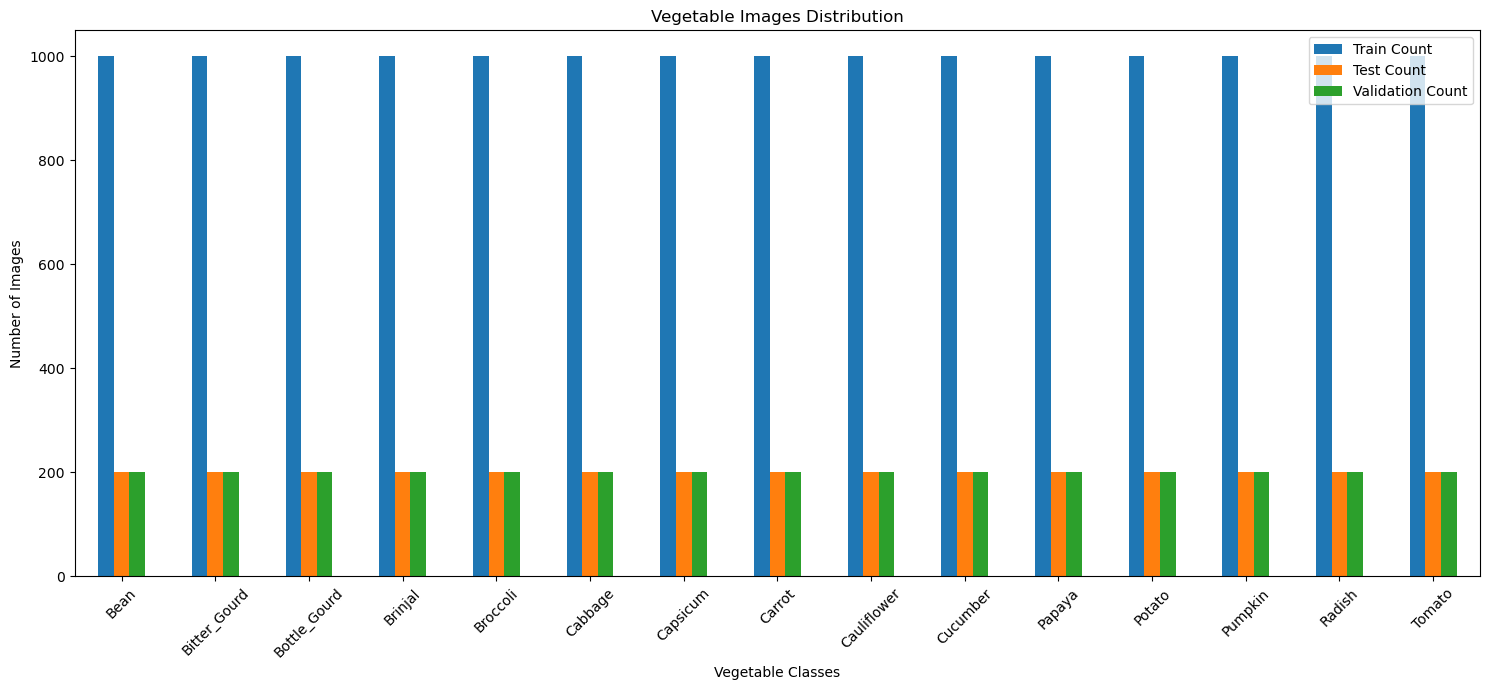

In [6]:
summary_df.plot(
    x="Vegetable",
    y=["Train Count", "Test Count", "Validation Count"],
    kind="bar",
    figsize=(15, 7)
)

plt.title("Vegetable Images Distribution")
plt.xlabel("Vegetable Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

In [8]:
validation_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [9]:
train_ds = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    seed=42,
    subset="training"
)

val_ds = validation_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    seed=42,
    subset="validation"
)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [10]:
print("Number of Classes:", train_ds.num_classes)
print("Class Names:", train_ds.class_indices)

Number of Classes: 15
Class Names: {'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


In [ ]:
model = Sequential([

    Conv2D(32, (3, 3), activation="relu",
           input_shape=(224, 224, 3)),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(512, activation="relu"),
    Dropout(0.5),

    Dense(15, activation="softmax")
])

c:\Users\ahmed\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [14]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 504s 1s/step - accuracy: 0.4283 - loss: 1.7408 - val_accuracy: 0.6683 - val_loss: 0.9714
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 530s 1s/step - accuracy: 0.6518 - loss: 1.0427 - val_accuracy: 0.7407 - val_loss: 0.7705
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 538s 1s/step - accuracy: 0.7496 - loss: 0.7602 - val_accuracy: 0.8600 - val_loss: 0.4048
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 542s 1s/step - accuracy: 0.7865 - loss: 0.6600 - val_accuracy: 0.8750 - val_loss: 0.3558
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 497s 1s/step - accuracy: 0.8220 - loss: 0.5603 - val_accuracy: 0.8767 - val_loss: 0.3752
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 470s 1s/step - accuracy: 0.8388 - loss: 0.5070 - val_accuracy: 0.9217 - val_loss: 0.2483
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 442s 1s/step - accuracy: 0.8544 - loss: 0.4512 - val_accuracy: 0.9277 - val_loss: 0.2289
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 468s 1s/step - accuracy: 0.8658 - loss: 0.4205 - val_accu

In [15]:
train_loss, train_accuracy = model.evaluate(train_ds)

print("Training Accuracy:", train_accuracy)
print("Training Loss:", train_loss)

375/375 ━━━━━━━━━━━━━━━━━━━━ 130s 347ms/step - accuracy: 0.9663 - loss: 0.1049
Training Accuracy: 0.9663333296775818
Training Loss: 0.1049136146903038


In [16]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Accuracy:", val_accuracy)
print("Validation Loss:", val_loss)

94/94 ━━━━━━━━━━━━━━━━━━━━ 16s 173ms/step - accuracy: 0.9810 - loss: 0.0631
Validation Accuracy: 0.9810000061988831
Validation Loss: 0.06305307149887085


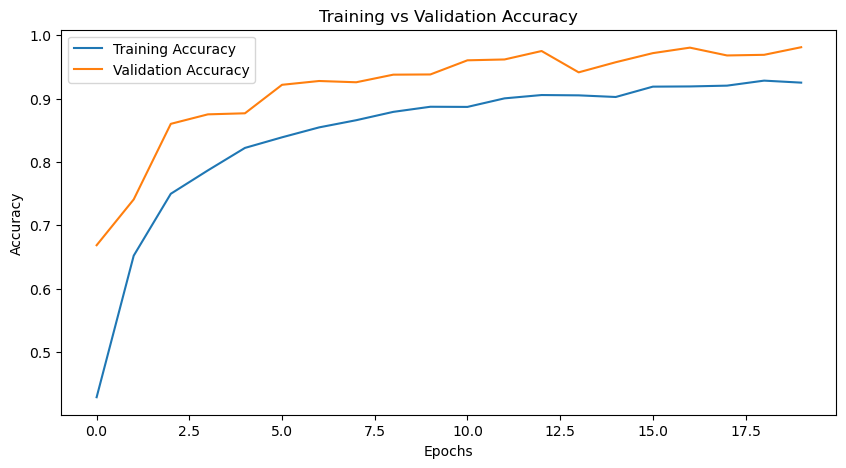

In [17]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

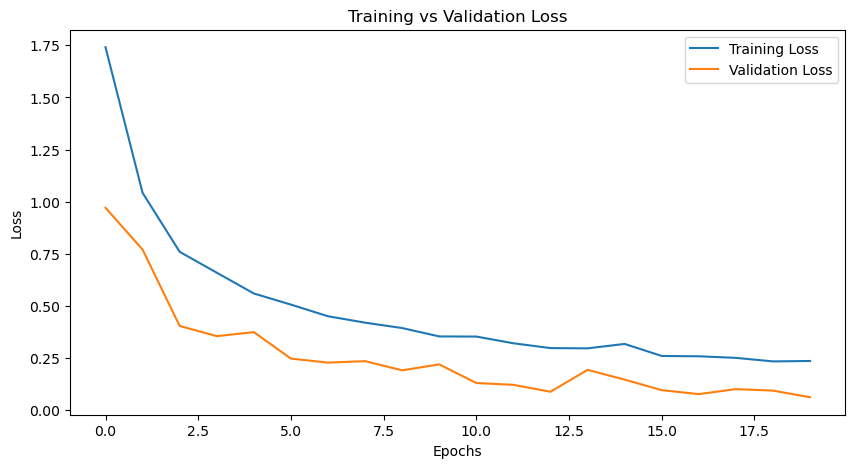

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()